<a href="https://colab.research.google.com/github/Gabioxdj46/NovaRetail-analysis/blob/main/Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [5]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Configuración para ver mejor las tablas
pd.set_option("display.max_columns", None)


### Cargar Dataset

In [6]:
# Cargar el dataset desde TripleTen o GitHub

import os
import pandas as pd

# Ruta original utilizada en TripleTen
ruta_tripleten = "/datasets/novaretail_comportamiento_clientes_2024.csv"

# Ruta pública del dataset en GitHub
url_github = "https://raw.githubusercontent.com/Gabioxdj46/NovaRetail-analysis/main/data/novaretail_comportamiento_clientes_2024.csv"

# Seleccionar la ruta disponible
if os.path.exists(ruta_tripleten):
    df = pd.read_csv(ruta_tripleten)
else:
    df = pd.read_csv(url_github)

# Comprobar que los datos se cargaron correctamente
print("Dimensiones del dataset:", df.shape)

df.info()

Dimensiones del dataset: (15000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [7]:
# mostrar las primeras 5 filas
df.head()


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


In [8]:
# Dimensiones del dataset
print("Filas y columnas:", df.shape)
# Nombres de columnas
df.columns

Filas y columnas: (15000, 12)


Index(['id_cliente', 'edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
       'gasto_publicidad_dirigida', 'satisfaccion', 'miembro_premium',
       'abandono', 'tipo_dispositivo', 'region', 'ingreso_anual'],
      dtype='object')

In [9]:
# Revisar valores faltantes
df.isna().sum()


,0
id_cliente,0
edad,0
nivel_ingreso,0
visitas_mes,0
compras_mes,0
gasto_publicidad_dirigida,0
satisfaccion,0
miembro_premium,0
abandono,0
tipo_dispositivo,0


In [10]:
# Revisar duplicados exactos
print("Filas duplicadas:", df.duplicated().sum())
# Revisar IDs de cliente duplicados
print("IDs duplicados:", df["id_cliente"].duplicated().sum())

Filas duplicadas: 0
IDs duplicados: 0


In [11]:
# Resumen estadístico de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio.
  
- Después de revisar la estructura del dataset, los tipos de datos, los valores nulos y los valores únicos por columna, no se identifican columnas que requieran cambios obligatorios en los datos o una limpieza adicional.

- Las variables numéricas (`edad`, `nivel_ingreso`, `visitas_mes`, `compras_mes`, `gasto_publicidad_dirigida`, `satisfaccion` e `ingreso_anual`) -están definidas correctamente para un análisis numérico.

- Las variables binarias (`miembro_premium` y `abandono`) están codificadas como 0 y 1, por lo que no requieren transformación adicional para un análisis como punto biserial.

- Las variables categóricas (`tipo_dispositivo` y `region`) están correctamente definidas como categorías de negocio. La columna `id_cliente` se mantiene como identificador único y no se utilizará como variable explicativa en el análisis de correlación.



#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
Estas variables se usarán para un análisis de correlación numérica mediante Pearson y Spearman. La columna `ingreso_anual` será la métrica principal del análisis, ya que representa el ingreso anual generado por cada cliente para NovaRetail.

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.
Estas variables podrán analizarse contra variables numéricas mediante punto biserial.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

La columna `id_cliente` funciona como identificador único del cliente y no será utilizada como variable explicativa en correlaciones. Las columnas `tipo_dispositivo` y `region` sí podrán utilizarse para analizar asociaciones categóricas mediante V de Cramér.
Estas variables están correctamente definidas y no requieren transformación adicional.

In [12]:
# Corregir el tipo de dato
# No se requieren cambios de tipo de datos.
# Las variables numericas, binarias y categoricas estan correctamente definidas.
#Se conserva
#-id_cliente como identificador
#-miembro_premium y abandono como variables binarias 0/1
#-tipo_dispositivo y region como variables categoricas.

In [13]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [14]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas = ["edad",
    "nivel_ingreso",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "ingreso_anual"
]
df[columnas_numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.26,11.49,18.0,30.00,38.00,46.00,75.00
nivel_ingreso,15000.0,30019.70,9833.17,8000.0,23127.10,30023.74,36768.44,74790.84
visitas_mes,15000.0,10.03,3.16,1.0,8.00,10.00,12.00,25.00
compras_mes,15000.0,1.21,1.11,0.0,0.00,1.00,2.00,8.00
gasto_publicidad_dirigida,15000.0,20.15,10.88,0.0,12.31,19.73,27.29,75.51
satisfaccion,15000.0,3.60,0.69,1.0,3.10,3.60,4.10,5.00
ingreso_anual,15000.0,36.59,34.48,0.0,0.00,30.70,58.22,244.69


✍️ **Comentario**:

Diagnóstico inicial de variables numéricas

- `edad` —La edad de los clientes esta entre los 18 a 75 años, con un promedio aproximado de 38 años. Los valores se encuentran en un rango razonable para clientes adultos y no se observan edades negativas o inconsistentes.
  
- `nivel_ingreso` — El ingreso estimado de los clientes presenta valores entre 8,000 y aproximadamente 74,790. Esta variable muestra variabilidad considerable entre clientes y puede ser relevante para explicar este comportamiento y el valor económico.

- `visitas_mes` — El número de visitas mensuales va de 1 a 25, con una mediana cercana a 10 visitas. Esto indica que los usuarios tienen distintos niveles de actividad en la plataforma.

- `compras_mes` — Las compras mensuales van de 0 a 8. El valor 0 es válido, ya que algunos usuarios pueden visitar la plataforma sin realizar una compra.

- `gasto_publicidad_dirigida` — El gasto en publicidad dirigida va de 0 a aproximadamente 75.51. El valor 0 puede representar usuarios que no recibieron inversión publicitaria dirigida.

- `satisfaccion` — La satisfacción está en una escala de 1 a 5. Los valores se encuentran dentro del rango esperado para una calificación de satisfacción.

- `ingreso_anual` — Esta es la variable objetivo del análisis. Presenta valores desde 0 hasta aproximadamente 244.69. El valor 0 puede representar clientes que no generaron ingreso durante el periodo analizado.



#### Explorar variables binarias

In [15]:
# Verificar que cada columna tenga únicamente dos valores posibles
columnas_binarias = [
    "miembro_premium",
    "abandono"
]
for columna in columnas_binarias:
    print(f"\nColumna: {columna}")
    print("Valores únicos:", df[columna].unique())
    print("Conteo:")
    print(df[columna].value_counts().sort_index())
    print("Porcentaje:")
    print((df[columna].value_counts(normalize=True).sort_index() * 100).round(2))


Columna: miembro_premium
Valores únicos: [0 1]
Conteo:
miembro_premium
0    12911
1     2089
Name: count, dtype: int64
Porcentaje:
miembro_premium
0    86.07
1    13.93
Name: proportion, dtype: float64

Columna: abandono
Valores únicos: [0 1]
Conteo:
abandono
0    12739
1     2261
Name: count, dtype: int64
Porcentaje:
abandono
0    84.93
1    15.07
Name: proportion, dtype: float64


✍️ **Comentario**:

Diagnóstico inicial de variables binarias

- `miembro_premium` — La variable contiene los valores 0 y 1. La mayoría de los clientes no pertenecen al segmento premium, mientras que una proporción pequena sí está considerada como premium. La codificación es adecuada para el análisis con punto biserial frente a variables numéricas como ingreso_anual.

- `abandono` — La variable también contiene únicamente los valores 0 y 1. La mayoría de los clientes no abandonó la plataforma, mientras que una proporción menor, sí aparece marcada como abandono. Esta variable puede analizarse como variable binaria frente a métricas numéricas de comportamiento o de valor.

Ambas variables están correctamente codificadas y no requieren transformación adicional.


#### Explorar variables categóricas

In [16]:
# Verificar el número de valores únicos por variable categórica
columnas_categoricas = [
    "id_cliente",
    "tipo_dispositivo",
    "region"
]
df[columnas_categoricas].nunique()

,0
id_cliente,15000
tipo_dispositivo,3
region,4


In [17]:
# Explorar variables categóricas y cómo se distribuyen
for columna in ["tipo_dispositivo", "region"]:
    print(f"\nColumna: {columna}")
    print("Conteo:")
    print(df[columna].value_counts())
    print("Porcentaje:")
    print((df[columna].value_counts(normalize=True) * 100).round(2))


Columna: tipo_dispositivo
Conteo:
tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: count, dtype: int64
Porcentaje:
tipo_dispositivo
móvil         65.45
escritorio    24.80
tablet         9.75
Name: proportion, dtype: float64

Columna: region
Conteo:
region
norte    4395
oeste    3810
sur      3726
este     3069
Name: count, dtype: int64
Porcentaje:
region
norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: proportion, dtype: float64


✍️ **Comentario**:

Diagnóstico inicial de variables categóricas

- `id_cliente` — Esta variable funciona como identificador único del cliente. Tiene un valor diferente por cada registro, por lo que no se usará como una variable explicativa dentro de un análisis de asociación. Su utilidad principal es de identificar registros únicos.
  
- `tipo_dispositivo` — Presenta tres categorías: `móvil`, `escritorio` y `tablet`. La categoría con mayor presencia es `móvil`, seguida por `escritorio` y luego `tablet`. Esta variable puede ser útil para analizar diferencias de comportamiento según el dispositivo utilizado.

- `region` — Presenta cuatro categorías: `norte`, `oeste`, `sur` y `este`. Las regiones están distribuidas entre los clientes, aunque no exactamente en la misma proporción. Esta variable puede ser útil para evaluar si existen asociaciones entre ubicación geográfica y comportamiento o valor del cliente.

Las variables categóricas principales están correctamente definidas y no requieren transformación adicional.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- El dataset contiene 15,000 registros y 12 columnas, sin valores nulos identificados en la revisión inicial.
- No se identifican cambios necesarios de tipo de dato para continuar con el análisis.
- La columna `id_cliente` se considera un identificador único y no se usará como variable explicativa.
- Las variables `miembro_premium` y `abandono` se interpretan como variables binarias codificadas como 0 y 1.
- Las variables `tipo_dispositivo` y `region` se interpretan como variables categóricas.
- La variable `ingreso_anual` será la métrica principal del análisis, porque representa el ingreso anual generado por cada cliente para NovaRetail+.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

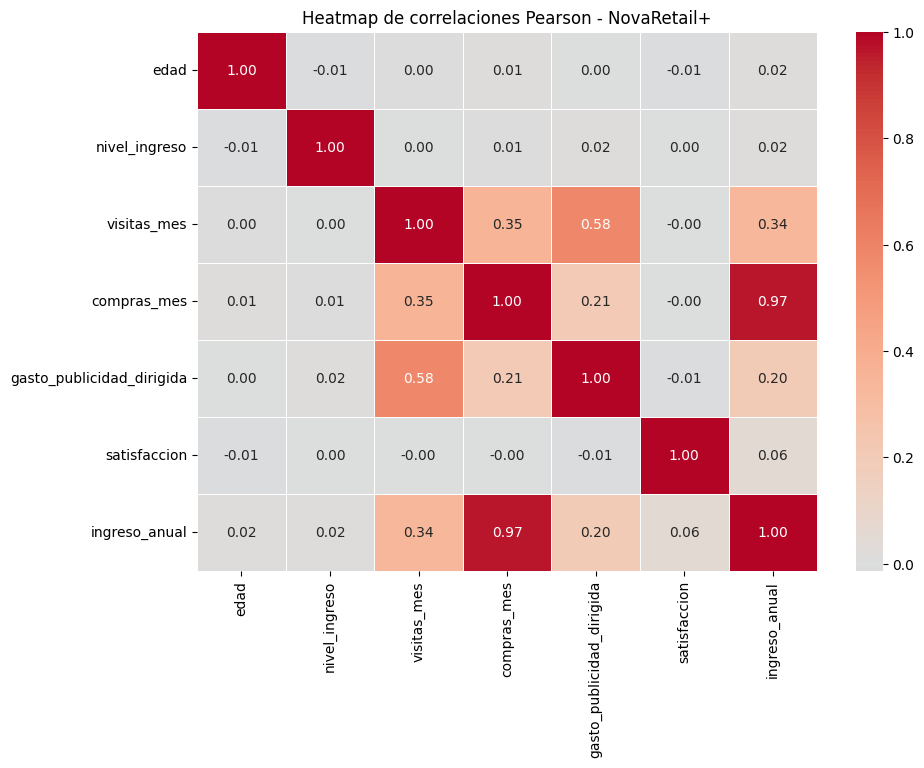

Correlaciones con ingreso_anual ordenadas por fuerza:
compras_mes                  0.967149
visitas_mes                  0.337147
gasto_publicidad_dirigida    0.197483
satisfaccion                 0.056171
edad                         0.017496
nivel_ingreso                0.017446
Name: ingreso_anual, dtype: float64


In [18]:
# Visualizar la matriz de correlación para identificar relaciones

corr_pearson = df[columnas_numericas].corr(method="pearson")

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_pearson,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Heatmap de correlaciones Pearson - NovaRetail+")
plt.show()

# Revisar correlaciones con la variable objetivo
corr_ingreso = corr_pearson["ingreso_anual"].drop("ingreso_anual")
corr_ingreso_ordenada = corr_ingreso.abs().sort_values(ascending=False)

print("Correlaciones con ingreso_anual ordenadas por fuerza:")
print(corr_ingreso.loc[corr_ingreso_ordenada.index])

✍️ **Comentario**:

Observaciones generales (Heatmap)  
- Se observa las relaciones iniciales entre las variables numéricas del dataset. Las correlaciones cercanas a 1 indican asociaciones positivas más fuertes, mientras que los valores cercanos a 0 indican relaciones débiles o casi inexistentes.

Observaciones respecto a `ingreso_anual`  
- Representa la métrica principal del proyecto. Las variables con mayor correlación absoluta frente a `ingreso_anual` serán revisadas con mayor detalle mediante scatterplots.

- Estas relaciones se interpretan como asociaciones exploratorias y no como evidencia de causalidad.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
- Se incluye un scatterplot general usando una muestra del dataset para visualizar patrones entre variables numéricas clave sin sobrecargar el notebook.
  - El gráfico permite observar de forma exploratoria si variables como `visitas_mes`, `compras_mes`, `gasto_publicidad_dirigida` y `nivel_ingreso` presentan alguna tendencia visual frente a `ingreso_anual`.
    
  - Describe brevemente qué patrones o tendencias observas.
  - De forma visual, la relacion mas clara que se observa es con compras_mes, parece ser una de las variables más asociadas visualmente con ingreso_anual.

  - También se observa una tendencia positiva entre `visitas_mes` e `ingreso_anual`, aunque con mayor dispersión.

  - La variable `gasto_publicidad_dirigida` muestra cierta asociación visual con variables de comportamiento y con `ingreso_anual`, aunque también presenta una cierta dispersión.

  - En cambio, `nivel_ingreso` no muestra una relación visual tan clara con `ingreso_anual`, ya que los puntos aparecen bastante dispersos.



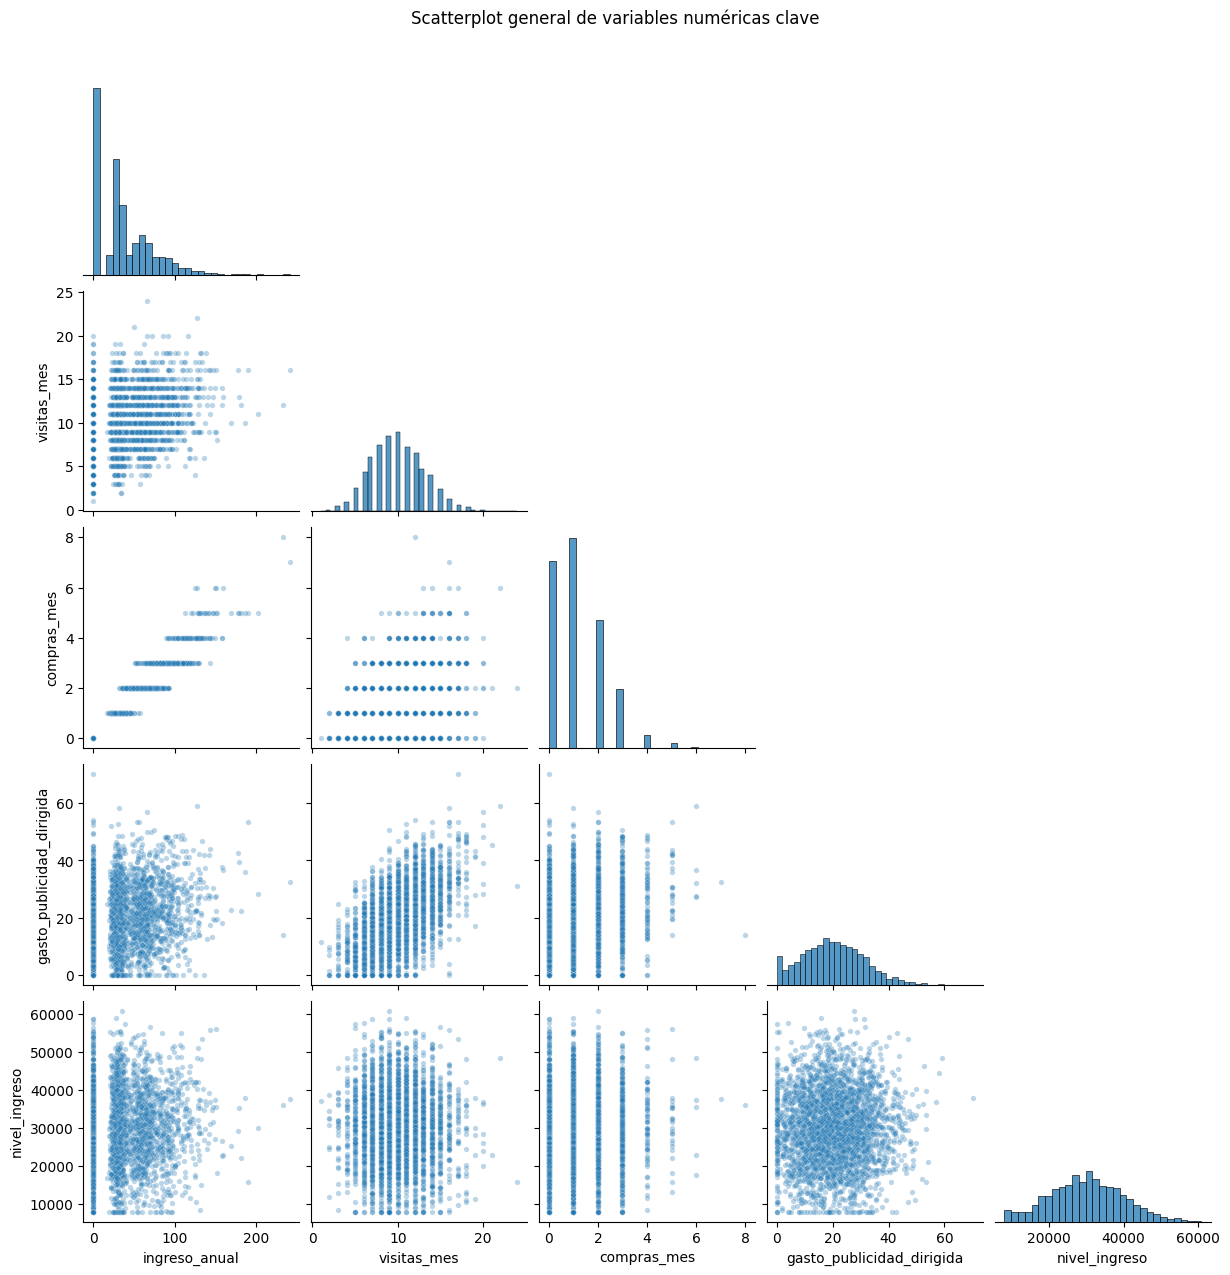

In [19]:
# Scatterplot general con variables clave

columnas_scatter_general = [
    "ingreso_anual",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "nivel_ingreso"
]

# Usamos una muestra para que el gráfico cargue más rápido
df_muestra = df[columnas_scatter_general].sample(n=3000, random_state=42)

sns.pairplot(
    df_muestra,
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.3,
        "s": 15
    }
)

# Agregar título general
plt.suptitle("Scatterplot general de variables numéricas clave", y=1.02)

plt.show()

### Scatterplot para pares clave

In [20]:
# Visualizar pares de variables con relaciones moderadas o fuertes

corr_ingreso = corr_pearson["ingreso_anual"].drop("ingreso_anual")
corr_ingreso_ordenada = corr_ingreso.abs().sort_values(ascending=False)

print("Correlaciones con ingreso_anual ordenadas por fuerza:")
print(corr_ingreso.loc[corr_ingreso_ordenada.index])

Correlaciones con ingreso_anual ordenadas por fuerza:
compras_mes                  0.967149
visitas_mes                  0.337147
gasto_publicidad_dirigida    0.197483
satisfaccion                 0.056171
edad                         0.017496
nivel_ingreso                0.017446
Name: ingreso_anual, dtype: float64


Variables seleccionadas para scatterplots clave:
['compras_mes', 'visitas_mes', 'gasto_publicidad_dirigida']


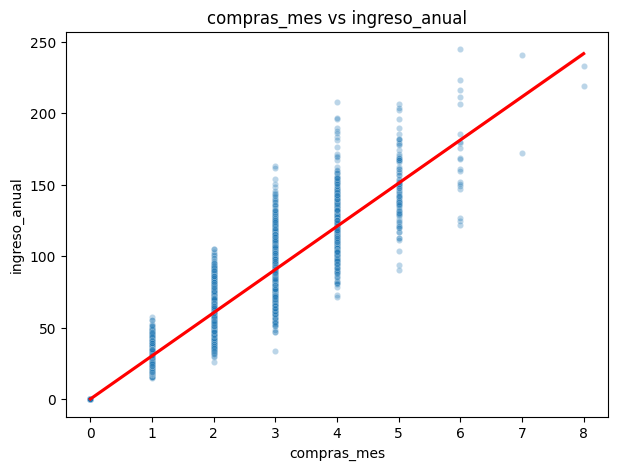

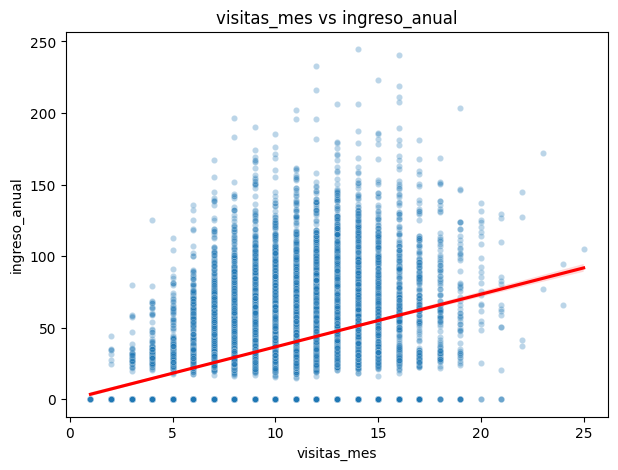

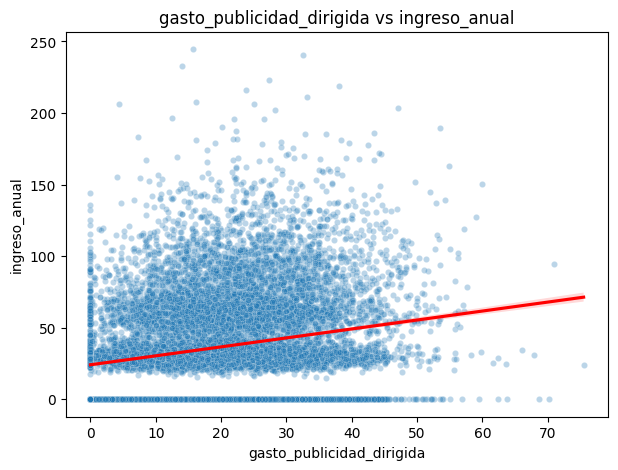

In [21]:
# Seleccionar las variables más asociadas con ingreso_anual según Pearson

variables_clave = corr_ingreso_ordenada.head(3).index.tolist()

print("Variables seleccionadas para scatterplots clave:")
print(variables_clave)

for variable in variables_clave:
    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=df,
        x=variable,
        y="ingreso_anual",
        alpha=0.3,
        s=20
    )

    sns.regplot(
        data=df,
        x=variable,
        y="ingreso_anual",
        scatter=False,
        color="red"
    )

    plt.title(f"{variable} vs ingreso_anual")
    plt.xlabel(variable)
    plt.ylabel("ingreso_anual")
    plt.show()

✍️ **Comentario**:  
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.

Observaciones iniciales (Scatterplot)

**compras_mes vs ingreso_anual**
- Dirección - Se observa una dirección positiva fuerte, cuando aumenta compras_mes, también tiende a aumentar ingreso_anual. También se ven columnas verticales porque compras_mes es una variable discreta. Es decir, solo puede tomar valores enteros. No existe 2.5 compras.
- Dispersion - La dispersión es media. Aunque la tendencia es clara, dentro de cada nivel de compras hay clientes con diferentes niveles de ingreso anual.
- Outliers - Se observan algunos clientes con ingresos anuales altos, especialmente en niveles mayores de compras. Estos puntos no se eliminan, ya que pueden representar clientes de alto valor.
- Posible colinealidad - Esta relación es fuerte visualmente, pero no se interpreta como colinealidad directamente porque `ingreso_anual` es la variable objetivo. Sin embargo, la relación sugiere que `compras_mes` es una variable muy relevante para explicar diferencias en el ingreso generado.
  
**visitas_mes vs ingreso_anual**
- Dirección - Aqui también se observa una dirección positiva, la línea roja sube, lo que indica que los clientes con más visitas mensuales tienden a generar más ingreso anual.
- Dispersion - Hay dispersion media alta. Esto quiere decir: isitar más la plataforma está asociado con mayor ingreso anual, pero no todos los clientes que visitan más, terminan generando mas ingreso.
- Outliers - Aqui se observan algunos clientes con ingresos anuales altos y también a clientes con muchas visitas pero con bajo ingreso anual.
- Posible colinealidad - No se identifica colinealidad directamente en este gráfico. La variable `visitas_mes` parece aportar información relacionada con la actividad del cliente, aunque debe analizarse junto con otras variables como `compras_mes`.

**gasto_publicidad_dirigida vs ingreso_anual**
- Direccion - Se observa una dirección positiva, porque la línea roja sube. Esto significa, que a mayor gasto de publicidad dirigida, tiende a observarse mayor ingreso anual pero la relacion no es perfecta y debe interpretrase con cuidado.
- Dispersion - Tiene una dispersion bastante alta, se ven muchos clientes con distintos niveles de gasto_publicidad_dirigida que generan ingresos anuales bajos, medios o altos.
- Outliers - Se observan algunos clientes con gasto publicitario alto o ingreso anual alto. Estos casos pueden representar clientes con comportamientos poco frecuentes o segmentos de mayor valor.
- Posible colinealidad - No se confirma colinealidad solo con este gráfico. La relación debe interpretarse como asociación visual y será complementada con coeficientes de correlación en la siguiente sección.


## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [22]:
# Calcular correlación entre variables relevantes

columnas_numericas = [
    "edad",
    "nivel_ingreso",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "ingreso_anual"
]

pearson_corr = df[columnas_numericas].corr(method="pearson")

print("Correlación Pearson:")
print(pearson_corr.round(3))


Correlación Pearson:
                            edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000         -0.009        0.005        0.015   
nivel_ingreso             -0.009          1.000        0.001        0.007   
visitas_mes                0.005          0.001        1.000        0.354   
compras_mes                0.015          0.007        0.354        1.000   
gasto_publicidad_dirigida  0.000          0.017        0.579        0.208   
satisfaccion              -0.007          0.002       -0.003       -0.004   
ingreso_anual              0.017          0.017        0.337        0.967   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                           0.000        -0.007   
nivel_ingreso                                  0.017         0.002   
visitas_mes                                    0.579        -0.003   
compras_mes                                    0.208        -0.004   
gasto_public

In [23]:
# Calcular correlación entre variables relevantes

spearman_corr = df[columnas_numericas].corr(method="spearman")

print("Correlación Spearman:")
print(spearman_corr.round(3))

Correlación Spearman:
                            edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000         -0.008        0.005        0.016   
nivel_ingreso             -0.008          1.000        0.001        0.009   
visitas_mes                0.005          0.001        1.000        0.333   
compras_mes                0.016          0.009        0.333        1.000   
gasto_publicidad_dirigida  0.003          0.015        0.559        0.193   
satisfaccion              -0.008          0.005       -0.001       -0.002   
ingreso_anual              0.016          0.025        0.321        0.967   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                           0.003        -0.008   
nivel_ingreso                                  0.015         0.005   
visitas_mes                                    0.559        -0.001   
compras_mes                                    0.193        -0.002   
gasto_publi

In [24]:
# Comparar correlaciones con ingreso_anual

correlaciones_ingreso = pd.DataFrame({
    "Pearson": pearson_corr["ingreso_anual"].drop("ingreso_anual"),
    "Spearman": spearman_corr["ingreso_anual"].drop("ingreso_anual")
})

correlaciones_ingreso["Fuerza_Pearson"] = correlaciones_ingreso["Pearson"].abs()

correlaciones_ingreso = correlaciones_ingreso.sort_values(
    by="Fuerza_Pearson",
    ascending=False
)

correlaciones_ingreso.round(3)

,Pearson,Spearman,Fuerza_Pearson
compras_mes,0.967,0.967,0.967
visitas_mes,0.337,0.321,0.337
gasto_publicidad_dirigida,0.197,0.185,0.197
satisfaccion,0.056,0.061,0.056
edad,0.017,0.016,0.017
nivel_ingreso,0.017,0.025,0.017


✍️ **Comentario**:
Incluye qué ves: dirección, magnitud y posible colinealidad.

Observaciones de correlación

#### `compras_mes` vs `ingreso_anual`

- **Dirección:** la correlación es positiva tanto en Pearson como en Spearman.
- **Magnitud:** la relación es muy fuerte, con un valor de Pearson de 0.967 y Spearman de 0.967.
- **Colinealidad:** esta relación no se interpreta como colinealidad directamente, porque `ingreso_anual` es la variable objetivo. Sin embargo, la magnitud es alta indicando que `compras_mes` está muy relacionada con el valor económico generado.

#### `visitas_mes` vs `ingreso_anual`

- **Dirección:** la correlación es positiva.
- **Magnitud:** la relación es débil a moderada, con Pearson de 0.337 y Spearman de 0.321.
- **Colinealidad:** no representa colinealidad directa con `ingreso_anual`. Para evaluar colinealidad se revisan relaciones entre variables explicativas.

#### `gasto_publicidad_dirigida` vs `ingreso_anual`

- **Dirección:** la correlación es positiva.
- **Magnitud:** la relación es débil, con Pearson de 0.197 y Spearman de 0.185.
- **Colinealidad:** no se confirma colinealidad con esta relación, ya que se compara contra la variable objetivo.

#### Variables con relación muy débil

Las variables `satisfaccion`, `edad` y `nivel_ingreso` presentan correlaciones muy cercanas a 0 con `ingreso_anual`. Esto indica que, dentro de este análisis, no muestran una relación lineal ni monótona relevante con el ingreso anual generado.

En general, Pearson y Spearman muestran resultados similares, lo que sugiere que las relaciones identificadas son consistentes y no dependen únicamente de una relación lineal perfecta.


### Punto-biserial

In [25]:
# Calcular correlación entre variables relevantes

# Calcular correlación punto-biserial entre variables binarias e ingreso_anual
from scipy.stats import pointbiserialr

pares_punto_biserial = [
    ("miembro_premium", "ingreso_anual"),
    ("abandono", "ingreso_anual")
]

resultados_punto_biserial = []

for col_binaria, col_numerica in pares_punto_biserial:
    coeficiente, p_value = pointbiserialr(df[col_binaria], df[col_numerica])

    resultados_punto_biserial.append({
        "variable_binaria": col_binaria,
        "variable_numerica": col_numerica,
        "coeficiente": coeficiente,
        "magnitud": abs(coeficiente),
        "p_value": p_value
    })

resultados_punto_biserial = pd.DataFrame(resultados_punto_biserial)

resultados_punto_biserial.round(4)

,variable_binaria,variable_numerica,coeficiente,magnitud,p_value
0,miembro_premium,ingreso_anual,0.0931,0.0931,0.0000
1,abandono,ingreso_anual,-0.0028,0.0028,0.7295


✍️ **Comentario**:   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

#### `miembro_premium` vs `ingreso_anual`

- **Dirección:** la relación es positiva, con un coeficiente punto-biserial de 0.0931.
- **Magnitud:** la magnitud es muy baja, ya que el valor está cerca de 0.

#### `abandono` vs `ingreso_anual`

- **Dirección:** la relación es negativa, con un coeficiente punto-biserial de -0.0028.
- **Magnitud:** la magnitud es prácticamente nula.

En conjunto, el análisis punto-biserial muestra que las variables binarias evaluadas tienen una relación muy débil o casi inexistente con `ingreso_anual`. Estas relaciones se interpretan como asociaciones exploratorias y no como causalidad.


### V de Cramér

In [26]:
# Función para calcular V de Cramér

from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(df, col_1, col_2):
    tabla = pd.crosstab(df[col_1], df[col_2])

    chi2, p_value, dof, expected = chi2_contingency(tabla)

    n = tabla.values.sum()
    coef_v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

    return coef_v

In [27]:
# Aplicar V de Cramér en variables relevantes

pares_cramer = [
    ("tipo_dispositivo", "region"),
    ("tipo_dispositivo", "miembro_premium"),
    ("region", "miembro_premium"),
    ("tipo_dispositivo", "abandono"),
    ("region", "abandono"),
    ("miembro_premium", "abandono")
]

resultados_cramer = []

for col_1, col_2 in pares_cramer:
    coef_v = cramers_v(df, col_1, col_2)

    resultados_cramer.append({
        "variable_1": col_1,
        "variable_2": col_2,
        "cramers_v": coef_v
    })

resultados_cramer = pd.DataFrame(resultados_cramer)

resultados_cramer.round(4)


,variable_1,variable_2,cramers_v
0,tipo_dispositivo,region,0.0124
1,tipo_dispositivo,miembro_premium,0.0197
2,region,miembro_premium,0.0126
3,tipo_dispositivo,abandono,0.0072
4,region,abandono,0.0154
5,miembro_premium,abandono,0.1202


✍️ **Comentario**:
Incluye qué ves

### Observaciones V de Cramér

La V de Cramér se utilizó para medir la fuerza de asociación entre variables categóricas. A diferencia de Pearson, Spearman o punto-biserial, este coeficiente no indica una dirección positiva o negativa; solo indica qué tan fuerte es la asociación entre categorías.

Los resultados muestran valores muy bajos para la mayoría de los pares analizados. Las asociaciones entre `tipo_dispositivo` y `region`, `tipo_dispositivo` y `miembro_premium`, `region` y `miembro_premium`, `tipo_dispositivo` y `abandono`, y `region` y `abandono` se encuentran cerca de 0. Esto sugiere asociaciones muy débiles o prácticamente inexistentes entre estas variables.

El valor más alto se observa entre `miembro_premium` y `abandono`, con una V de Cramér de 0.1202. Esta asociación puede considerarse débil, ya que supera ligeramente 0.10, pero todavía está lejos de una asociación moderada o fuerte.

En conjunto, los resultados sugieren que las variables categóricas analizadas no presentan asociaciones fuertes entre sí. Estas asociaciones deben interpretarse como relaciones entre segmentos, no como causalidad.



## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**:


### Hallazgo 1 — Compras mensuales son el factor mas asociado con el ingreso anual

**Evidencia visual:**  
En los scatterplots de pares clave entre `compras_mes` e `ingreso_anual`, se observa una tendencia positiva clara . A medida que aumenta el número de compras mensuales, también aumenta los valores de ingreso anual. Los puntos aparecen agrupados en columnas porque `compras_mes` es una variable discreta, es decir, toma valores enteros como 0, 1, 2, 3 o más compras.

**Evidencia numérica:**  
La correlación de Pearson entre `compras_mes` e `ingreso_anual` es de 0.967, y la correlación de Spearman también es de 0.967. Ambos valores indican una asociación positiva muy fuerte.

**Interpretación:**  
Los clientes que realizan más compras mensuales tienden a generar mayor ingreso anual para NovaRetail. Esta es la relación más fuerte observada en el análisis y sugiere que la frecuencia de compra es un indicador clave del valor económico generado por los clientes.

**No podemos afirmar:**  
No podemos afirmar directamente que aumentar el número de compras causa automáticamente un mayor ingreso anual, ya que este análisis es correlacional. También es posible que la variable de `ingreso_anual` esté construida en parte a partir del comportamiento de compra, por lo que esta relación debe interpretarse con cuidado.

**Implicación de negocio:**  
NovaRetail debería priorizar estrategias orientadas a incrementar la frecuencia de compra, como campañas de recompra, recomendaciones personalizadas, promociones para clientes activos y programas de fidelización. Sin embargo, estas acciones deberían comprobarse posteriormente mediante pruebas controladas, como experimentos A/B, para comprobar su efecto real sobre el ingreso.


### Hallazgo 2 — `visitas_mes` tiene una asociación positiva con `ingreso_anual`

**Evidencia visual:**  
En el scatterplot entre `visitas_mes` e `ingreso_anual` se observa una tendencia positiva. La línea de tendencia tiende a subir, lo que indica que los clientes que tienen más visitas mensuales tienden a generar un mayor ingreso anual. Sin embargo, los puntos están bastante dispersos, por lo que la relación no es tan clara como en el caso de `compras_mes`.

**Evidencia numérica:**  
La correlación de Pearson entre `visitas_mes` e `ingreso_anual` es 0.337, mientras que la correlación de Spearman es 0.321. Ambos valores son positivos y de magnitud débil a moderada.

**Interpretación:**  
Una mayor actividad en la plataforma, está asociada con un mayor ingreso anual, pero la relación no es suficientemente fuerte como para considerar que las visitas son el principal factor de valor económico. Esto sugiere que tener mayor visitas en la plataforma puede ser una señal de interés, pero no todos los usuarios que visitan terminan comprando más o generando más ingreso.

**No podemos afirmar:**  
No podemos afirmar que aumentar las visitas causa directamente un mayor ingreso anual. Algunos usuarios pueden visitar muchas veces pero no realizan compras, mientras que otros ususarios pueden visitar menos y  realizar un mayor numero de compras.

**Implicación de negocio:**  
NovaRetail debería analizar de cómo convertir mejor las visitas en compras. La atencion no debería estar solo en aumentar tráfico, sino tambien en mejorar la conversión: recomendaciones más relevantes, una mejor experiencia en la navegación, promociones oportunas y reducción de fricciones en el proceso de compra.

### Hallazgo 3 — gasto_publicidad_dirigida se asocia débilmente con ingreso_anual

**Evidencia visual:**
En el scatterplot entre `gasto_publicidad_dirigida` e `ingreso_anual`, se observa una tendencia positiva pero con una alta dispersión. Hay
clientes con diferentes niveles de ingreso anual para valores similares de gasto publicitario, lo que indica que la relación visual no es fuerte.

**Evidencia numérica:**  
La correlación de Pearson entre `gasto_publicidad_dirigida` e `ingreso_anual` es 0.197, y la correlación de Spearman es 0.185. Estos valores
indican una asociación positiva débil. Además,`gasto_publicidad_dirigida` presenta una correlación moderada con `visitas_mes`, aproximadamente
0.579, lo que sugiere una relación más clara con actividad en la plataforma que con ingreso anual directo.

**Interpretación:**  
El gasto en publicidad dirigida está asociado positivamente con el ingreso anual, pero la magnitud de la relación es baja. Esto indica que la
publicidad dirigida puede estar relacionada con clientes de mayor actividad o exposición, pero no parece ser por sí sola estar asociado de manera
fuerte al ingreso generado.

**No podemos afirmar:**  
No podemos afirmar que aumentar el gasto publicitario habra un mayor ingreso anual. También es posible que NovaRetail asigne más publicidad a
clientes que ya muestran mayor actividad o potencial de compra.

**Implicación de negocio:**  
NovaRetail debería evaluar la eficiencia del gasto publicitario dirigido con métricas adicionales, como conversión, retorno sobre la inversión
publicitaria y pruebas A/B. El gasto publicitario debería analizarse junto con visitas a la plataforma y compras, para entender si realmente
impulsa ingresos o simplemente acompaña a clientes que ya eran más activos.

### Hallazgo 4 — Las variables binarias y categóricas presentan asociaciones débiles

**Evidencia visual:**  
No se generaron gráficos específicos para este hallazgo, ya que las variables binarias y categóricas fueron evaluadas principalmente mediante coeficientes adecuados para su tipo de dato: punto-biserial y V de Cramér.

**Evidencia numérica:**  
En el análisis punto-biserial, `miembro_premium` presenta una relación positiva muy débil con `ingreso_anual`, con un coeficiente de 0.0931. La variable `abandono` presenta una relación prácticamente nula con `ingreso_anual`, con un coeficiente de -0.0028.

En el análisis con V de Cramér, la mayoría de las asociaciones categóricas son muy débiles. Los valores entre `tipo_dispositivo`, `region`, `miembro_premium` y `abandono` se encuentran cerca de 0. El valor más alto se observa entre `miembro_premium` y `abandono`, con una V de Cramér de 0.1202, lo que representa una asociación débil.

**Interpretación:**  
Las variables binarias y categóricas evaluadas no parecen ser los principales factores asociados con el ingreso anual generado. Ser miembro premium muestra una asociación positiva muy leve con `ingreso_anual`, pero mucho menor que la observada en variables de comportamiento como `compras_mes`. Las variables `tipo_dispositivo` y `region` tampoco muestran asociaciones relevantes con premium o abandono.

**No podemos afirmar:**  
No podemos afirmar que ser premium cause mayor ingreso anual ni que el dispositivo o la región determinen el abandono o el valor del cliente. Las asociaciones observadas son débiles y no permiten conclusiones causales.

**Implicación de negocio:**  
NovaRetail no debería basar sus decisiones principales únicamente en región, dispositivo o estado premium. Estas variables pueden servir para segmentación secundaria, pero los resultados sugieren que los comportamientos de compra y actividad son más informativos para entender el ingreso anual generado.


## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**:



### **Limitaciones**
- Este análisis es correlacional y exploratorio, por lo tanto, no establece causalidad. Las relaciones encontradas indican asociación entre variables, pero no demuestran que una variable es causa por cambios en otra variable.

- La relación más fuerte que se observó es entre `compras_mes` e `ingreso_anual`, con una correlación de Pearson y Spearman de 0.967. Sin embargo, esta relación debe interpretarse con cuidado, ya que `ingreso_anual` podría estar directamente relacionado con el comportamiento de la compra del cliente.

- Algunas variables presentan relaciones débiles con `ingreso_anual`, como `gasto_publicidad_dirigida`, `satisfaccion`, `edad` y `nivel_ingreso`. Esto no significa que no sean importantes para el negocio, sino que en este análisis no muestran una relación fuerte con la métrica principal.

- Las variables categóricas y binarias analizadas, como `tipo_dispositivo`, `region`, `miembro_premium` y `abandono`, muestran asociaciones débiles en los coeficientes calculados. Por lo tanto, no se recomienda usarlas por sí solas como factores principales asociados al ingreso anual.

- El análisis no controla variables externas o variables ocultas que podrían influir en los resultados, como estacionalidad, campañas específicas, descuentos, categoría de producto, antigüedad del cliente o frecuencia histórica de compra.

- Los resultados se basan en los datos disponibles del dataset y representan una fotografía del comportamiento observado. Para tomar decisiones de negocio más firmes, sería necesario complementar este análisis con pruebas adicionales.

### **Próximos pasos**

#### 1. Profundizar el análisis de frecuencia de compra

Dado que `compras_mes` presenta una asociación más fuerte con `ingreso_anual`, se recomienda analizar con más detalle los perfiles de clientes según su frecuencia de compra. Por ejemplo, se podrían crear segmentos de clientes con baja, media y alta frecuencia de compra para comparar su ingreso anual promedio, comportamiento de visitas y respuesta a campañas.

#### 2. Analizar conversión entre visitas y compras

`visitas_mes` muestra una asociación positiva con `ingreso_anual`, aunque menor que `compras_mes`. Por ello, una opcion sería estudiar la conversión de visitas en compras. Esto permitiría identificar si el problema está en atraer usuarios, en la conversion de visitas a compras o en aumentar el valor de cada compra.

#### 3. Evaluar la eficiencia del gasto publicitario dirigido

La variable `gasto_publicidad_dirigida` presenta una asociación positiva débil con `ingreso_anual`, pero con una relación más clara con `visitas_mes`. Por ello, se recomienda evaluar si la publicidad dirigida está generando visitas de calidad y si esas visitas se estan convirtiendo en compras. Para esto sería útil calcular métricas como conversión, ingreso por usuario impactado y el retorno sobre la inversión publicitaria.

#### 4. Realizar pruebas A/B para validar impacto causal

Como el análisis correlacional no prueba causalidad, se recomienda diseñar experimentos A/B. Por ejemplo, se podría probar una campaña de recompra o una promoción personalizada en un grupo de clientes y comparar los resultados contra un grupo de control. Esto permitiría evaluar si una acción específica realmente genera mayor ingreso anual.

#### 5. Incorporar variables adicionales

Para mejorar el análisis, sería útil incluir variables como antigüedad del cliente, categoría de productos comprados, ticket promedio, descuentos recibidos, canal de adquisición, fechas de campañas y estacionalidad. Estas variables podrían ayudar a explicar mejor el ingreso anual y reducir el riesgo de interpretaciones incompletas.

#### 6. Construir un modelo predictivo como siguiente etapa

Después del análisis correlacional, se podría construir un modelo predictivo para estimar `ingreso_anual` a partir de variables de comportamiento. Este modelo debería evaluarse con métricas adecuadas y siempre interpretarse con cuidado, diferenciando predicción de causalidad.

In [28]:
##https://github.com/Gabioxdj46/NovaRetail-analysis